# Q3 — Can we predict a country's trust in AI?

**Target:** `trust_ai_pct` — the % of people in a country who say they trust AI. It is a number (25%–79%), so this is a **regression** problem.

| Step | What we do |
|---|---|
| **0** | Clean the data (same approach as the EDA) |
| **1** | Choose the inputs — the 4 from the feature-selection report, and why |
| **2** | Run each model and fine-tune its settings |
| **3** | Compare the models — what the numbers mean for the business and for the data |
| **4** | Pick the final model and explain it |
| **5** | Caveats — what to be careful about |

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from collections import Counter
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

from scipy import stats
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_root = Path.cwd().resolve()
if not (project_root / "datasets").exists():
    project_root = project_root.parent
DATA_DIR = project_root / "datasets"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})
BLUE, ORANGE, GREY, LIGHT, INK = "#2a78d6", "#eb6834", "#b4b2ac", "#d9d8d3", "#52514e"

df = pd.read_csv(DATA_DIR / "ai_trust_by_country.csv")
df2 = pd.read_csv(DATA_DIR / "ai_benefit_perception_trend.csv")

## Step 0 — Clean the data

Same checks as the EDA notebook: size, missing values, duplicates, and whether the values make sense.

In [3]:
datasets = {"Trust (main)": df, "Benefit trend (Q4 only)": df2}
summary = pd.DataFrame([{
    "Dataset": name, "Rows": d.shape[0], "Columns": d.shape[1],
    "Missing values": int(d.isnull().sum().sum()), "Duplicate rows": int(d.duplicated().sum())}
    for name, d in datasets.items()])
display(summary)

pct_cols = [c for c in df.columns if c.endswith("_pct")]
print("Main dataset — survey % columns range from", df[pct_cols].min().min(), "to", df[pct_cols].max().max())
print("Main dataset — duplicate countries:", df["country"].duplicated().sum())
print("\nTrend dataset — missing values by column:")
print(df2.isnull().sum()[df2.isnull().sum() > 0])
print("Trend dataset — countries not in the main dataset:", df2.loc[~df2["in_country_trust_dataset"], "country"].tolist())

,Dataset,Rows,Columns,Missing values,Duplicate rows
0,Trust (main),47,43,0,0
1,Benefit trend (Q4 only),32,6,4,0


Main dataset — survey % columns range from 5 to 96
Main dataset — duplicate countries: 0

Trend dataset — missing values by column:
benefit_gt_drawback_2023_pct    2
change_2023_2024_pp             2
dtype: int64
Trend dataset — countries not in the main dataset: ['Indonesia', 'Thailand', 'Peru', 'Malaysia']


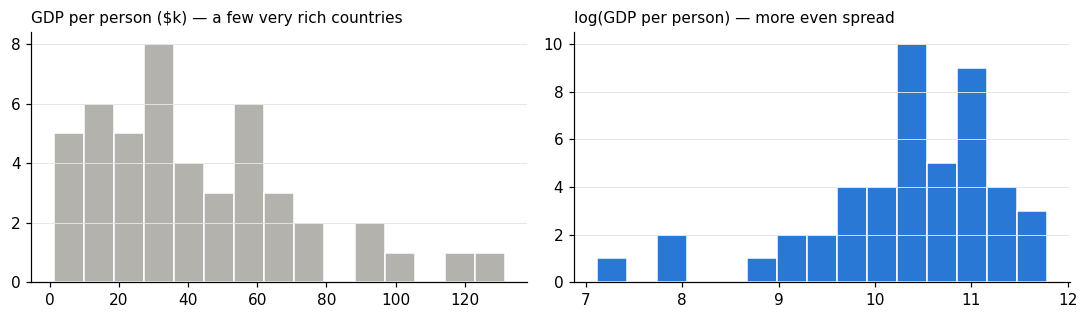

In [4]:
# Skewed money/size columns -> log scale (as in the feature-selection report)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(df["gdp_per_capita_usd"] / 1000, bins=15, color=GREY, edgecolor="white")
axes[0].set_title("GDP per person ($k) — a few very rich countries", loc="left", fontsize=10)
axes[1].hist(np.log(df["gdp_per_capita_usd"]), bins=15, color=BLUE, edgecolor="white")
axes[1].set_title("log(GDP per person) — more even spread", loc="left", fontsize=10)
for a in axes: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

df["log_gdp"] = np.log(df["gdp_per_capita_usd"])

### Cleaning decisions

| Check / action | Result | Why |
|---|---|---|
| Missing values (main dataset) | **None** | Nothing to fill in |
| Duplicates | **None** | Each country appears once |
| Survey % values | All between 0 and 100 | No impossible values |
| Trend dataset | China & Switzerland have no 2023 value; Indonesia, Thailand, Peru, Malaysia are not in the main dataset | Only matters for Q4 — not used in this model |
| **Removed: identifiers** | `country`, `iso3` | Names, not information |
| **Removed: leakage** | `accept_ai_pct`, `risks_outweigh_benefits_pct`, `sentiment` | These are basically other ways of measuring trust itself — like predicting this month's revenue from this month's sales |
| **Removed: too thin** | `region` | 9 categories for 47 countries (some regions have only 2) |
| **Transformed** | GDP → `log_gdp` | GDP ranges from ~$1k to ~$130k; the log stops a few rich countries from dominating |

**Result:** a clean table of 47 countries, ready for modelling.

## Step 1 — Which inputs, and why

We use the **4 inputs chosen in the feature-selection report**:

| Input | What it means | Stands for the group… |
|---|---|---|
| `safeguards_sufficient_pct` | % who think AI safeguards/rules are good enough | AI readiness & governance (also: literacy, AI training, awareness of regulations, using AI at work) |
| `increased_efficiency_pct` | % who say AI made them more efficient at work | Workplace payoff (also: increased revenue, employer training, AI strategy/policies) |
| `couldnt_work_without_ai_pct` | % who couldn't do their job without AI | Dependence on AI (also: relying on AI without learning or checking) |
| `log_gdp` | How rich the country is | Economic context — kept as a **control** |

**How Yutong chose them (summary):** she grouped inputs that rise and fall together, scored every input with four tests (correlation with trust, mutual information, Lasso, Random Forest importance), kept the one input per group with ≥3 of 4 votes and the strongest link to trust, and added GDP as a control. One input per group means the same information isn't fed into the model twice.

Quick check of the 4 inputs below.

In [5]:
FEATURES = ["safeguards_sufficient_pct", "increased_efficiency_pct", "couldnt_work_without_ai_pct", "log_gdp"]
TARGET = "trust_ai_pct"
X, y = df[FEATURES], df[TARGET].values

def vif(X):
    Z = StandardScaler().fit_transform(X); out = []
    for j in range(Z.shape[1]):
        o = np.delete(Z, j, axis=1)
        out.append(1 / (1 - LinearRegression().fit(o, Z[:, j]).score(o, Z[:, j])))
    return out

check = pd.DataFrame({
    "Spearman ρ with trust": [stats.spearmanr(df[c], y)[0] for c in FEATURES],
    "p-value": [stats.spearmanr(df[c], y)[1] for c in FEATURES],
    "VIF (overlap with the other 3)": vif(X),
}, index=FEATURES)
check["p-value"] = check["p-value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
check.round(2)

,Spearman ρ with trust,p-value,VIF (overlap with the other 3)
safeguards_sufficient_pct,0.83,<0.001,3.71
increased_efficiency_pct,0.82,<0.001,5.13
couldnt_work_without_ai_pct,0.72,<0.001,3.70
log_gdp,-0.51,<0.001,1.86


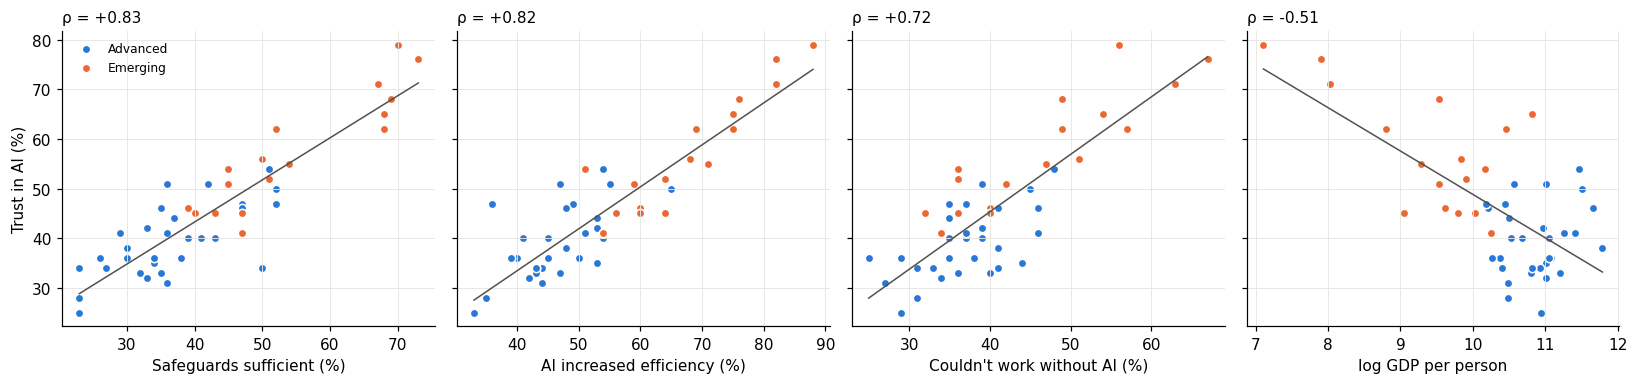

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
names = ["Safeguards sufficient (%)", "AI increased efficiency (%)", "Couldn't work without AI (%)", "log GDP per person"]
for ax, col, name in zip(axes, FEATURES, names):
    for et, c in [("advanced", BLUE), ("emerging", ORANGE)]:
        m = df["economy_type"] == et
        ax.scatter(df.loc[m, col], y[m], s=30, color=c, edgecolor="white", linewidth=1, label=et.capitalize())
    b = np.polyfit(df[col], y, 1); xs = np.linspace(df[col].min(), df[col].max(), 10)
    ax.plot(xs, np.polyval(b, xs), color=INK, lw=1)
    ax.set_xlabel(name); ax.set_title(f"ρ = {stats.spearmanr(df[col], y)[0]:+.2f}", loc="left", fontsize=10)
axes[0].set_ylabel("Trust in AI (%)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Findings
- **All 4 inputs are clearly linked to trust** (Spearman |ρ| from 0.51 to 0.83, all p < 0.001). Safeguards, efficiency and reliance on AI go **up** with trust; GDP goes **down** (richer countries are more sceptical).
- **Overlap between them is moderate:** every VIF is about 5 or below (efficiency is highest at ≈5.1). Many of the 36 original inputs had VIFs above 10. Lower overlap means fewer repeats, but it doesn't remove overlap completely.
- **The scatter plots look roughly like straight lines**, which hints that a simple linear model could work well.
- Emerging economies (orange) sit in the top-right: high on the inputs *and* on trust.

## Step 2 — Run each model and fine-tune it

### The models

| Model | How it works, in one line | Settings we tune |
|---|---|---|
| **Baseline** | Always predicts the average trust (≈46%) | — (the bar to beat) |
| **Linear Regression** | Fits a straight-line formula: trust = a + b₁·safeguards + … | None — it has no settings to tune |
| **Ridge Regression** | Linear Regression with a penalty that keeps the weights small and stable | `alpha` = strength of the penalty |
| **Decision Tree (CART)** | Asks yes/no questions ("safeguards > 50%?") and predicts the average of each final group | `max_depth` = how many questions deep · `min_samples_leaf` = minimum countries in each final group |
| **Random Forest** | Builds many slightly different trees and averages them | number of trees · `max_depth` · `min_samples_leaf` · `max_features` = how many inputs each split may consider |

### 2a. How we test: repeated 5-fold cross-validation (not a 70/30 split)

**70/30 split:** train on 33 countries, test on the other 14, report that one score.

**Repeated 5-fold cross-validation:** split the 47 countries into 5 groups → train on 4 groups (~38 countries), predict the 5th → rotate so **every country is predicted once** by a model that never saw it → repeat with 3 different shuffles and average.

**Why it matters here:** with only 14 test countries, a 70/30 score depends heavily on *which* 14 you happen to get. The test below runs the **same model (Linear Regression, same 4 inputs) 100 times** each way, each time with a different random shuffle.

,70/30 split,Repeated 5-fold CV
Avg error — best run (pp),2.17,3.49
Avg error — typical run (pp),3.61,3.60
Avg error — worst run (pp),5.29,3.82
R² — worst run,0.49,0.85
R² — best run,0.96,0.87


Example — Lithuania (the hardest country to predict):
  70/30 runs where Lithuania is in the test set: avg error 4.07 pp
  70/30 runs where it is not:                    avg error 3.40 pp


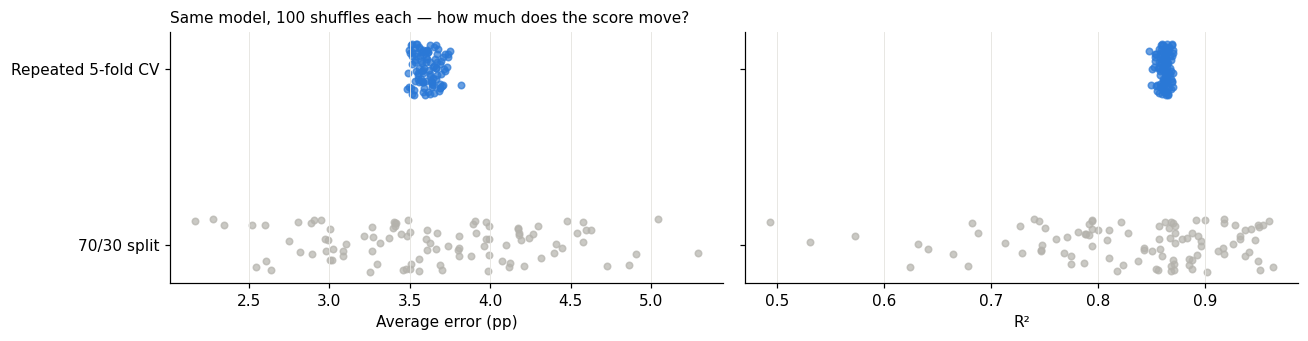

In [7]:
from sklearn.model_selection import train_test_split, cross_val_predict

split_mae, split_r2, lith_in_test = [], [], []
cv_mae, cv_r2 = [], []
lith = df.index[df["country"] == "Lithuania"][0]

for s in range(100):
    # 70/30: one split
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=s)
    p = LinearRegression().fit(X_tr, y_tr).predict(X_te)
    split_mae.append(mean_absolute_error(y_te, p)); split_r2.append(r2_score(y_te, p))
    lith_in_test.append(lith in X_te.index)
    # repeated 5-fold: 3 shuffles x 5 folds, averaged
    reps = [cross_val_predict(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=3 * s + k))
            for k in range(3)]
    cv_mae.append(np.mean([mean_absolute_error(y, p) for p in reps]))
    cv_r2.append(np.mean([r2_score(y, p) for p in reps]))

split_mae, split_r2, cv_mae, cv_r2, lith_in_test = map(np.array, [split_mae, split_r2, cv_mae, cv_r2, lith_in_test])

compare_cv = pd.DataFrame({
    "70/30 split": [split_mae.min(), np.median(split_mae), split_mae.max(), split_r2.min(), split_r2.max()],
    "Repeated 5-fold CV": [cv_mae.min(), np.median(cv_mae), cv_mae.max(), cv_r2.min(), cv_r2.max()],
}, index=["Avg error — best run (pp)", "Avg error — typical run (pp)", "Avg error — worst run (pp)",
          "R² — worst run", "R² — best run"]).round(2)
display(compare_cv)

print(f"Example — Lithuania (the hardest country to predict):")
print(f"  70/30 runs where Lithuania is in the test set: avg error {split_mae[lith_in_test].mean():.2f} pp")
print(f"  70/30 runs where it is not:                    avg error {split_mae[~lith_in_test].mean():.2f} pp")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, vals, label in [(axes[0], (split_mae, cv_mae), "Average error (pp)"), (axes[1], (split_r2, cv_r2), "R²")]:
    for row, (v, col, name) in enumerate([(vals[0], GREY, "70/30 split"), (vals[1], BLUE, "Repeated 5-fold CV")]):
        jitter = np.random.default_rng(row).uniform(-0.15, 0.15, len(v))
        ax.scatter(v, row + jitter, s=18, color=col, alpha=0.7)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["70/30 split", "Repeated 5-fold CV"]); ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_title("Same model, 100 shuffles each — how much does the score move?", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

### Findings
- **The typical score is the same both ways (≈3.6 pp).** Cross-validation doesn't make the model better. It makes the **measurement more reliable**.
- **70/30 is a lottery:** the same model scored anywhere from **2.2 to 5.3 pp** error and **R² 0.49 to 0.96**, just depending on which 14 countries were in the test set. Repeated 5-fold stayed within **3.5–3.8 pp** and **R² 0.85–0.87**.
- **Example — Lithuania:** when this hard-to-predict country is in the 70/30 test set, the error is ≈4.1 pp; when it isn't, ≈3.4 pp. With 5-fold, every country is tested exactly once, so no single country can hide or dominate.
- **Less data wasted:** each model learns from ~38 countries instead of 33.
- **Why it matters:** the gap between the linear models and the next model (Random Forest) is only ≈0.7 pp, but a 70/30 score swings by ≈3 pp. With 70/30, luck could easily decide which model "wins".

### 2b. Tune each model, and test it fairly (nested cross-validation)

Some models have settings (see the table above). To tune them without cheating, we use two loops:
- **Outer loop (the exam):** the repeated 5-fold cross-validation from 2a — the score we report.
- **Inner loop (practice tests):** *inside* each outer training set (~38 countries), try the settings with another 5-fold split and keep the best. The exam countries are **never** used to choose settings — otherwise we'd pick whichever setting happened to suit them, and the score would look better than it really is.

We also run every model with its **default settings**, to show what tuning changes. Takes ~2 minutes.

In [8]:
inner = KFold(5, shuffle=True, random_state=0)
N_REPEATS = 3

def tuned_models():
    return {
        "Baseline (average)": DummyRegressor(strategy="mean"),
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge Regression": GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                                         {"ridge__alpha": np.logspace(-3, 3, 25)},
                                         cv=inner, scoring="neg_mean_absolute_error"),
        "Decision Tree (CART)": GridSearchCV(DecisionTreeRegressor(random_state=0),
                                             {"max_depth": [1, 2, 3, 4, 5, 6, None],
                                              "min_samples_leaf": [1, 2, 3, 5, 8]},
                                             cv=inner, scoring="neg_mean_absolute_error"),
        "Random Forest": RandomizedSearchCV(RandomForestRegressor(random_state=0),
                                            {"n_estimators": [100, 300],
                                             "max_depth": [2, 3, 4, 6, None],
                                             "min_samples_leaf": [1, 2, 3, 5],
                                             "max_features": [1.0, 0.75, 0.5]},
                                            n_iter=10, cv=inner, scoring="neg_mean_absolute_error",
                                            random_state=0, n_jobs=-1),
    }

def default_models():
    return {
        "Baseline (average)": DummyRegressor(strategy="mean"),
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge Regression": make_pipeline(StandardScaler(), Ridge()),            # alpha = 1
        "Decision Tree (CART)": DecisionTreeRegressor(random_state=0),           # grows until every leaf is pure
        "Random Forest": RandomForestRegressor(random_state=0, n_jobs=-1),       # 100 full-depth trees
    }

def run(models_fn):
    preds = {n: np.zeros((N_REPEATS, len(y))) for n in models_fn()}
    best_params = {n: [] for n in preds}
    for r in range(N_REPEATS):
        for tr, te in KFold(5, shuffle=True, random_state=r).split(X):
            for name, model in models_fn().items():
                model.fit(X.iloc[tr], y[tr])                       # tuning happens inside, on training countries only
                preds[name][r, te] = model.predict(X.iloc[te])
                if hasattr(model, "best_params_"):
                    best_params[name].append(tuple(sorted(model.best_params_.items())))
    return preds, best_params

def score(preds):
    rows = []
    for name, P in preds.items():
        s = np.array([[mean_absolute_error(y, p), mean_squared_error(y, p) ** 0.5, r2_score(y, p),
                       np.mean(np.abs(y - p) <= 5)] for p in P])
        rows.append({"Model": name, "MAE": s[:, 0].mean(), "MAE spread (3 reshuffles)": s[:, 0].std(), "RMSE": s[:, 1].mean(),
                     "R²": s[:, 2].mean(), "Within ±5 pp": s[:, 3].mean()})
    return pd.DataFrame(rows).set_index("Model")

tuned_preds, best_params = run(tuned_models)
default_preds, _ = run(default_models)
tuned, default = score(tuned_preds), score(default_preds)

def most_common(name):
    if not best_params[name]:
        return "— (no settings to tune)"
    (params, n), = Counter(best_params[name]).most_common(1)
    nice = ", ".join(f"{k.replace('ridge__', '')}={round(float(v), 2) if isinstance(v, (float, np.floating)) else v}"
                     for k, v in params)
    return f"{nice}  ({n} of {len(best_params[name])} rounds)"

all_models = pd.DataFrame({
    "MAE — default": default["MAE"],
    "MAE — tuned": tuned["MAE"],
    "R² — default": default["R²"],
    "R² — tuned": tuned["R²"],
    "Best settings found (most common)": [most_common(n) for n in tuned.index],
}, index=tuned.index)
all_models.round(2)

,MAE — default,MAE — tuned,R² — default,R² — tuned,Best settings found (most common)
Model,,,,,
Baseline (average),9.86,9.86,-0.04,-0.04,— (no settings to tune)
Linear Regression,3.66,3.66,0.86,0.86,— (no settings to tune)
Ridge Regression,3.63,3.67,0.86,0.86,alpha=10.0 (5 of 15 rounds)
Decision Tree (CART),5.89,5.91,0.69,0.68,"max_depth=4, min_samples_leaf=2 (3 of 15 rounds)"
Random Forest,4.42,4.35,0.81,0.81,"max_depth=6, max_features=0.5, min_samples_leaf=1, n_estimators=300 (7 of 15 rounds)"


### Findings
- **All five models are in one table.** Baseline and Linear Regression have no settings, so their default and tuned scores are the same.
- **Tuning changed every model by less than 0.1 pp**, which is about the size of the normal wobble between reshuffles. The "best" settings also kept changing between rounds (e.g. Ridge's best alpha was the same in only 5 of 15 rounds), so with ~38 training countries there's no clearly better setting to find.
- **Takeaway:** choosing the right *model* mattered much more than fine-tuning its settings.

## Step 3 — Compare the models

### How to read the metrics

| Metric | Plain English | Good when |
|---|---|---|
| **MAE** | On average, the prediction is off by this many percentage points | Lower |
| **RMSE** | Like MAE, but big misses count extra. Much bigger than MAE = a few large misses | Lower |
| **R²** | Share of the differences in trust *between countries* that the model explains (1 = all, 0 = no better than guessing the average) | Higher |
| **Within ±5 pp** | Share of countries predicted within 5 points of their real value | Higher |

In [9]:
table = tuned.copy()
table["Within ±5 pp"] = (table["Within ±5 pp"] * 100).round(0).astype(int).astype(str) + "%"
table.round(2)

,MAE,MAE spread (3 reshuffles),RMSE,R²,Within ±5 pp
Model,,,,,
Baseline (average),9.86,0.13,12.59,-0.04,29%
Linear Regression,3.66,0.16,4.68,0.86,73%
Ridge Regression,3.67,0.13,4.64,0.86,71%
Decision Tree (CART),5.91,0.29,6.95,0.68,43%
Random Forest,4.35,0.08,5.40,0.81,65%


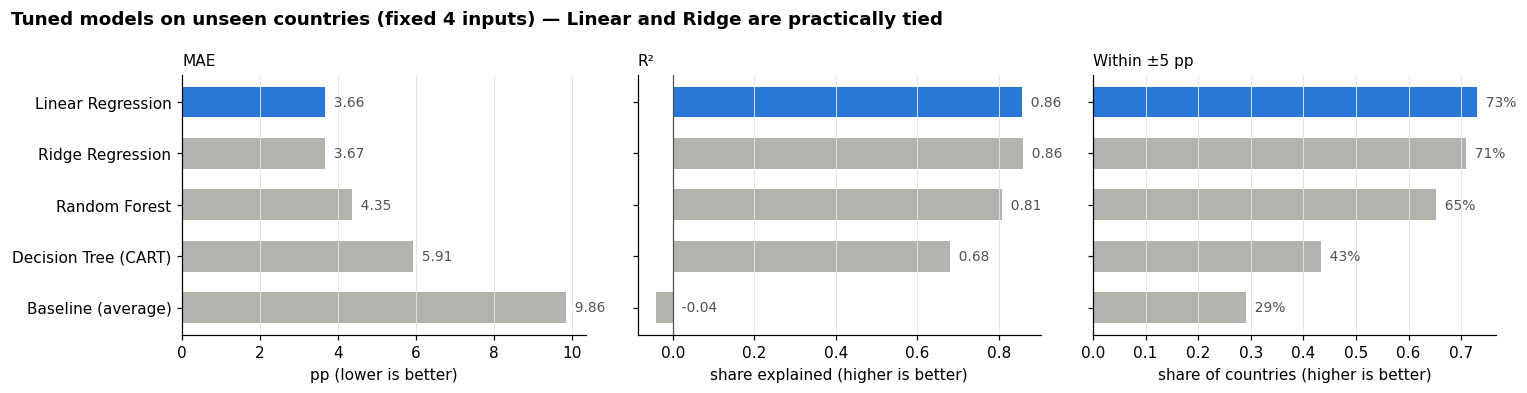

In [10]:
best = tuned.drop("Baseline (average)")["MAE"].idxmin()
order = tuned.sort_values("MAE", ascending=False).index
colors = [BLUE if m == best else GREY for m in order]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, metric, unit in zip(axes, ["MAE", "R²", "Within ±5 pp"], ["pp (lower is better)", "share explained (higher is better)", "share of countries (higher is better)"]):
    vals = tuned.loc[order, metric]
    ax.barh(order, vals, color=colors, height=0.6)
    for i, v in enumerate(vals):
        lab = f"{v:.0%}" if metric == "Within ±5 pp" else f"{v:.2f}"
        ax.text(max(v, 0), i, "  " + lab, va="center", fontsize=9, color=INK)
    ax.set_title(f"{metric}", loc="left", fontsize=10); ax.set_xlabel(unit)
    ax.grid(axis="y", visible=False)
    if metric == "R²": ax.axvline(0, color=INK, lw=0.8)
fig.suptitle("Tuned models on unseen countries (fixed 4 inputs) — Linear and Ridge are practically tied", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### Findings — what the comparison means

**In business terms (for a non-technical audience)**
- **Guessing the average for every country is about 10 points off. Linear Regression is about 3.7 points off on average**, so roughly two-thirds less error.
- **About 3 in 4 countries are predicted within ±5 points** of their real trust level (guessing the average manages only 3 in 10).
- **It accounts for about 86% of the variation in trust between countries.** That describes how well it fits, not what *causes* trust.
- **Some misses are bigger:** 4 countries are off by 8+ points (see the country table in Step 4).
- **The simple models win.** Straight-line models beat the tree-based ones, so the final model is easy to explain and check, not a "black box".
- ⚠️ The 4 inputs were picked using all 47 countries, so these scores are a bit optimistic (see caveat 2).

**In data / prediction terms**
- **Linear and Ridge are practically tied** (3.66 vs 3.67 pp tuned; Ridge with default settings even scores 3.63). We can't say one is better.
- **Overlap didn't cause a clear prediction problem:** Ridge, which is designed for overlapping inputs, didn't predict better. But this does **not** prove the overlap is harmless — the individual weights of overlapping inputs can still be unstable (see caveats).
- **Random Forest (4.35 pp) and especially the single Decision Tree (5.91 pp) do worse.** The relationships look roughly straight (Step 1). Trees predict in "steps" — the average of a small group of countries — and with ~38 training countries those steps are coarse.
- **RMSE (4.68) is a bit above MAE (3.66)**, so there are some larger misses (e.g. Lithuania), but no single country dominates the error.
- **"MAE spread" is the variation across 3 reshuffles of the same 47 countries.** It's small (0.1–0.3 pp), so the order of models didn't flip when we reshuffled. It is **not** a confidence interval and doesn't prove the ranking would hold on new data.

## Step 4 — Pick the final model and explain it

### ✅ Final choice: **Linear Regression**

| Reason | Detail |
|---|---|
| **As accurate as any model** | Practically tied with Ridge for the lowest error (≈3.7 pp, R² ≈ 0.86) |
| **Simplest** | No settings to tune, so there's nothing that can be accidentally fitted to these 47 countries |
| **Easy to explain** | One formula: each input has one number saying how much predicted trust moves |

Since Linear and Ridge perform the same, we pick Linear **for simplicity**, not because it's proven better.

Below: the final formula (trained on all 47 countries), predicted vs actual, what each input adds, and every country's result.

In [11]:
final = LinearRegression().fit(X, y)
terms = " ".join(f"{'+' if b >= 0 else '−'} {abs(b):.2f}×{c}" for b, c in zip(final.coef_, FEATURES))
print("Final model (trained on all 47 countries):\n")
print(f"predicted trust = {final.intercept_:.1f} {terms}")

Final model (trained on all 47 countries):

predicted trust = 20.7 + 0.37×safeguards_sufficient_pct + 0.31×increased_efficiency_pct + 0.25×couldnt_work_without_ai_pct − 1.75×log_gdp


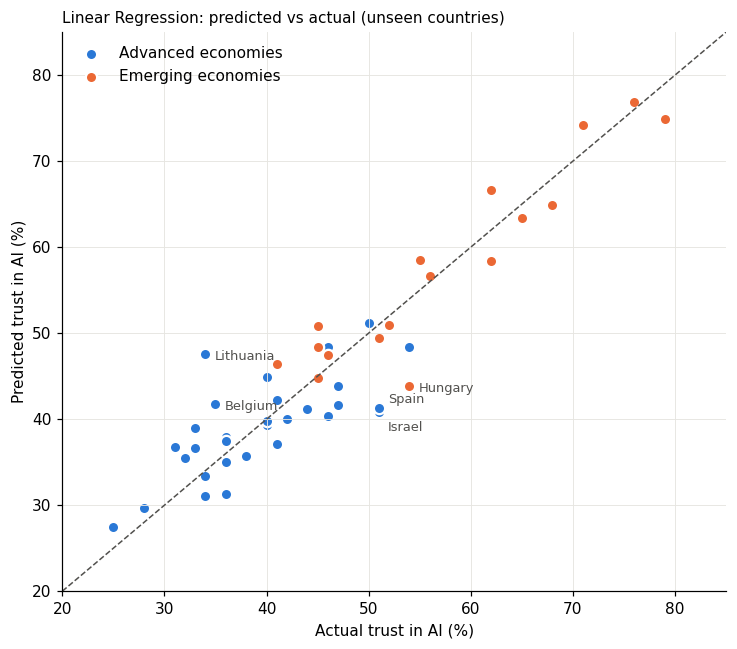

In [12]:
pred = tuned_preds["Linear Regression"].mean(axis=0)     # unseen-country predictions
resid = y - pred
fig, ax = plt.subplots(figsize=(6.8, 6))
for et, c in [("advanced", BLUE), ("emerging", ORANGE)]:
    m = (df["economy_type"] == et).values
    ax.scatter(y[m], pred[m], s=55, color=c, edgecolor="white", linewidth=1.5, label=f"{et.capitalize()} economies")
ax.plot([20, 85], [20, 85], "--", color=INK, lw=1); ax.set_xlim(20, 85); ax.set_ylim(20, 85)
nudge = {"Israel": (6, -12), "Spain": (6, 3)}
for i in np.argsort(-np.abs(resid))[:5]:
    ax.annotate(df.loc[i, "country"], (y[i], pred[i]), xytext=nudge.get(df.loc[i, "country"], (6, -4)),
                textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xlabel("Actual trust in AI (%)"); ax.set_ylabel("Predicted trust in AI (%)")
ax.set_title("Linear Regression: predicted vs actual (unseen countries)", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

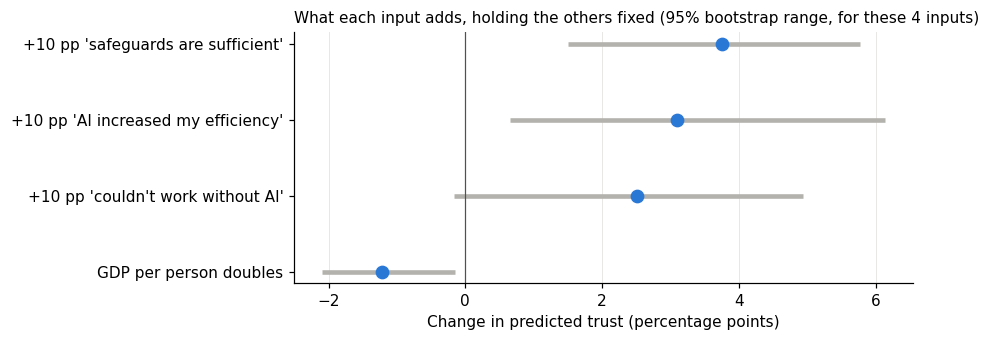

,effect,low,high
+10 pp 'safeguards are sufficient',3.7,1.5,5.8
+10 pp 'AI increased my efficiency',3.1,0.6,6.1
+10 pp 'couldn't work without AI',2.5,-0.2,4.9
GDP per person doubles,-1.2,-2.1,-0.2


In [13]:
rng = np.random.default_rng(0)
boot = np.array([LinearRegression().fit(X.iloc[i], y[i]).coef_ for i in (rng.integers(0, 47, 47) for _ in range(1000))])
scale = np.array([10, 10, 10, np.log(2)])
eff = pd.DataFrame({"effect": final.coef_ * scale,
                    "low": np.percentile(boot, 2.5, 0) * scale, "high": np.percentile(boot, 97.5, 0) * scale},
                   index=["+10 pp 'safeguards are sufficient'", "+10 pp 'AI increased my efficiency'",
                          "+10 pp 'couldn't work without AI'", "GDP per person doubles"])
fig, ax = plt.subplots(figsize=(8.5, 3.2))
yp = np.arange(len(eff))[::-1]
ax.errorbar(eff["effect"], yp, xerr=[eff["effect"] - eff["low"], eff["high"] - eff["effect"]],
            fmt="o", color=BLUE, ecolor=GREY, elinewidth=3, markersize=8)
ax.axvline(0, color=INK, lw=0.8); ax.set_yticks(yp); ax.set_yticklabels(eff.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in predicted trust (percentage points)")
ax.set_title("What each input adds, holding the others fixed (95% bootstrap range, for these 4 inputs)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
eff.round(1)

### Findings — what the final model says
- **+10 pp "safeguards are sufficient" → ≈ +3.7 pp predicted trust** (range +1.5 to +5.8). The largest estimated effect, but its range overlaps with efficiency's, so we can't say for sure it's stronger.
- **+10 pp "AI increased my efficiency" → ≈ +3.1 pp** (range +0.6 to +6.1). Clearly positive.
- **+10 pp "couldn't work without AI" → ≈ +2.5 pp**, but its range crosses zero (−0.2 to +4.9), so we can't be sure of its direction on its own. It overlaps with the other two inputs.
- **Doubling GDP per person → ≈ −1.2 pp** (range −2.1 to −0.2). Richer countries are slightly less trusting, even after accounting for the rest.
- ⚠️ **These ranges assume the 4 inputs are fixed.** They don't include the extra uncertainty from having chosen those inputs using the same data, so treat them as rough guides.

### Every country: actual vs predicted

Predictions come from cross-validation, so each country was predicted by a model that **had not seen it**.
**Off by** = actual − predicted (positive = the country trusts AI *more* than the model expected).
Flag: ✅ within ±5 pp · ⚠️ off by 5–8 pp · ❌ off by 8+ pp.

In [14]:
all_countries = pd.DataFrame({
    "Economy": df["economy_type"].values,
    "Actual trust (%)": y,
    "Predicted (%)": pred.round(1),
    "Off by (pp)": (y - pred).round(1),
}, index=df["country"])
all_countries["Flag"] = np.select([all_countries["Off by (pp)"].abs() >= 8, all_countries["Off by (pp)"].abs() >= 5],
                                  ["❌ 8+ pp", "⚠️ 5–8 pp"], "✅ within 5")
print(all_countries["Flag"].value_counts().to_string(), "\n")
all_countries.sort_values("Off by (pp)")

Flag
✅ within 5    35
⚠️ 5–8 pp      8
❌ 8+ pp        4 



,Economy,Actual trust (%),Predicted (%),Off by (pp),Flag
country,,,,,
Lithuania,advanced,34,47.6,-13.6,❌ 8+ pp
Belgium,advanced,35,41.8,-6.8,⚠️ 5–8 pp
France,advanced,33,38.9,-5.9,⚠️ 5–8 pp
Colombia,emerging,45,50.8,-5.8,⚠️ 5–8 pp
Czech Republic,advanced,31,36.8,-5.8,⚠️ 5–8 pp
Poland,emerging,41,46.5,-5.5,⚠️ 5–8 pp
Italy,advanced,40,44.9,-4.9,✅ within 5
Saudi Arabia,emerging,62,66.6,-4.6,✅ within 5
Netherlands,advanced,33,36.7,-3.7,✅ within 5


In [15]:
# What makes the biggest misses different? Their values vs the typical country of the same economy type
cols = {"safeguards_sufficient_pct": "Safeguards OK", "increased_efficiency_pct": "Efficiency",
        "couldnt_work_without_ai_pct": "Can't work w/o AI", "gdp_per_capita_usd": "GDP ($)",
        "concerned_left_behind_pct": "Worried left behind*", "experienced_benefits_pct": "Experienced benefits*",
        "aware_regulations_pct": "Aware of rules*", "concerned_negative_pct": "Worried about harms*"}
big = all_countries.index[all_countries["Off by (pp)"].abs() >= 5]
detail = df.set_index("country").loc[big, list(cols)].rename(columns=cols)
detail.insert(0, "Off by (pp)", all_countries.loc[big, "Off by (pp)"])
typical = df.groupby("economy_type")[list(cols)].median().rename(columns=cols)
typical.index = ["Typical " + i for i in typical.index]
print("* = not in the model\n")
out = pd.concat([detail.sort_values("Off by (pp)"), typical])
display(out.round(0).assign(**{"Off by (pp)": out["Off by (pp)"].round(1)}))

* = not in the model



,Off by (pp),Safeguards OK,Efficiency,Can't work w/o AI,GDP ($),Worried left behind*,Experienced benefits*,Aware of rules*,Worried about harms*
Lithuania,-13.6,50.0,43.0,41.0,32959.0,35.0,80.0,14.0,74.0
Belgium,-6.8,34.0,53.0,44.0,60750.0,50.0,71.0,10.0,84.0
France,-5.9,32.0,47.0,40.0,48986.0,36.0,72.0,8.0,81.0
Colombia,-5.8,40.0,64.0,40.0,8562.0,57.0,88.0,13.0,85.0
Czech Republic,-5.8,36.0,44.0,27.0,35917.0,38.0,77.0,5.0,78.0
Poland,-5.5,47.0,54.0,34.0,28420.0,49.0,76.0,10.0,82.0
Latvia,5.3,52.0,36.0,37.0,26312.0,37.0,83.0,24.0,76.0
Greece,5.6,35.0,48.0,41.0,26948.0,51.0,85.0,7.0,87.0
Norway,5.6,51.0,54.0,48.0,94594.0,53.0,75.0,32.0,76.0
Spain,9.7,42.0,47.0,39.0,38627.0,54.0,84.0,8.0,85.0


### Why are some countries far off?
**Overall:** 35 of 47 countries (74%) are within ±5 pp, 8 are off by 5–8 pp, and 4 are off by 8+ pp. The tables above compare each big miss with the *typical* country of the same economy type. Columns marked * are **not** in the model.

**❌ Off by 8+ pp**
- **Lithuania (actual 34%, predicted ≈48%):** 50% of Lithuanians say AI safeguards are sufficient, far above the typical advanced economy (36%). Safeguards is the input the model leans on most, so it expected high trust. But that confidence in the rules doesn't show up as personal trust. Fewer people also worry about being left behind (35% vs 40%), so there may be less pressure to adopt AI.
- **Israel (51% vs ≈41%):** safeguards (36%) is exactly typical and GDP is high, so the model expects average-to-low trust. But Israelis report more benefits from AI (84% vs 77%) and more worry about being left behind (48% vs 40%), and neither is in the model.
- **Hungary (54% vs ≈44%):** Hungary is classed as emerging, but its inputs look like an advanced economy's (safeguards 45%, efficiency 51%, can't work without AI 36%, all below typical emerging levels). So the model predicts advanced-level trust, while Hungary's actual trust is closer to other emerging economies.
- **Spain (51% vs ≈41%):** its 4 inputs are all close to a typical advanced economy, so the model predicts typical trust. But Spain is well above typical on two things the model doesn't use: worry about being left behind (54% vs 40%) and experienced benefits (84% vs 77%).

**⚠️ Off by 5–8 pp**
- **Belgium (−6.8):** more AI use at work than typical (efficiency 53%, can't work without AI 44%), so the model expected more trust than the 35% reported.
- **France (−5.9):** inputs are close to typical, but trust (33%) is simply lower than similar countries; few worry about being left behind (36%).
- **Czech Republic (−5.8):** lower GDP than most advanced economies pushes the prediction up, but its trust (31%) is among the lowest.
- **Colombia (−5.8):** low GDP pushes the prediction up, but confidence in safeguards (40%) is low for an emerging economy.
- **Poland (−5.5):** above-typical confidence in safeguards (47%) and a lower GDP made the model expect ≈47%; actual is 41%.
- **Latvia (+5.3):** few say AI improved their efficiency (36%), which pulls the prediction down, yet confidence in safeguards (52%), awareness of AI rules (24%) and experienced benefits (83%) are all high.
- **Greece (+5.6):** above typical on worry about being left behind (51%) and experienced benefits (85%).
- **Norway (+5.6):** very high GDP (≈$95k) pulls the prediction down, but Norway has by far the highest awareness of AI rules (32% vs 10% typical) and many worry about being left behind (53%).

**The pattern:** countries that trust AI *more* than predicted tend to have more people worried about being left behind and more who say they've experienced benefits. Those are two things the model doesn't use, so they're its main blind spots. This is a pattern in the data, not proof. The real-world reasons (politics, media coverage, recent AI news) can't be checked with this dataset.

## Step 5 — Caveats

| # | Caveat | What it means for us |
|---|---|---|
| 1 | **Only 47 countries** | Every number has some wobble. Treat the scores as "about", not exact. |
| 2 | **The 4 inputs were picked using all 47 countries** | The test countries had already helped choose the inputs, so our scores (≈3.7 pp, R² ≈ 0.86) are a bit optimistic. Yutong's report measured this: redoing the selection inside each fold lowered her R² from 0.78 to 0.73 and raised RMSE from 4.4 to 5.0. (Her R² is averaged over small test groups, so it reads lower than ours.) **Expect somewhat larger errors on new countries than shown here.** |
| 3 | **Inputs and target come from the same survey** | People who feel positive about AI tend to answer positively to many questions. Part of the high R² is this general positivity, not a deep "driver" of trust. |
| 4 | **Association, not causation** | We can't say "improve safeguards and trust will rise by 3.7 pp". Trust might just as well make people believe safeguards are fine. |
| 5 | **The weights of overlapping inputs are uncertain** | The 4 inputs still overlap somewhat (VIF up to ≈5). Predictions are fine, but how the model splits credit between inputs can shift with small changes in the data. |
| 6 | **Effect ranges are rough** | The bootstrap ranges in Step 4 assume the 4 inputs are fixed, so they understate the true uncertainty. |
| 7 | **"Couldn't work without AI" is the weakest input** | Its effect range crosses zero. Present it lightly. |
| 8 | **Blind spots** | Worry about being left behind and experienced benefits aren't in the model; countries high on these tend to trust AI more than predicted (Step 4). |
| 9 | **Country averages, not individuals** | "Countries with more X trust AI more" doesn't mean "people with more X trust AI more". |
| 10 | **Uneven coverage** | 30 advanced vs 17 emerging economies; only 2–3 countries for Africa, Oceania and North America. |
| 11 | **One snapshot in time** | The model says nothing about how trust changes over time (that's Q4). |

## One-slide summary

| | |
|---|---|
| **Question** | Can we predict a country's trust in AI? |
| **Inputs (4)** | Safeguards are sufficient · AI increased efficiency · Couldn't work without AI · GDP per person (control), from Yutong's feature selection |
| **Models compared** | Baseline (average) · Linear Regression · Ridge · Decision Tree (CART) · Random Forest, tested with repeated 5-fold cross-validation and tuned fairly (nested) |
| **Final model** | **Linear Regression**: tied with Ridge, chosen because it's simpler |
| **Accuracy** | ≈3.7 pp average error (guessing the average: ≈9.9 pp) · R² ≈ 0.86 · 35 of 47 countries within ±5 pp. Somewhat optimistic, because the inputs were chosen using all countries |
| **Biggest misses** | Lithuania (trusts less than predicted); Israel, Hungary, Spain (trust more) |
| **Key message** | Countries where more people think AI safeguards are adequate and see efficiency gains at work tend to trust AI more; richer countries tend to be slightly more sceptical |
| **Main caveats** | 47 countries · inputs chosen on all data · inputs from the same survey · association, not causation |

**Say it like this:** *"We compared four machine-learning models against a simple baseline using repeated cross-validation. Linear and Ridge Regression performed best and were practically tied, so we chose Linear Regression because it's simpler. On countries it hadn't seen, it was about 3.7 percentage points off on average and accounted for about 86% of the variation in trust, with 35 of 47 countries within 5 points. Countries where people believe AI safeguards are adequate tend to trust AI more, but this is an association, not proof of cause."*